# CISC 473 — Environmental sound classification, step by step
## Frozen AST features, microphone filtering, and CPCP

**Group 10 · Masih Hashemi, Anand Swamy, Kiarash Mirkamandari**

This notebook implements the first five coding steps from our project plan. 

| Step | What you will build | What to look for |
|---|---|---|
| 1 | ESC-50 download, splits, audio preprocessing | Valid files and no source overlap |
| 2 | Frozen pretrained AST and resumable feature cache | One 768-number vector per clip |
| 3 | Linear classifier, three seeds, evaluation | Actual predictions and a learning curve |
| 4 | Synthetic microphone responses and augmentation baseline | Unseen-filter evaluation and spectrogram comparison |
| 5 | CPCP and unprotected projection | Matched comparison and projection checks |



### Setup — install dependencies
Run this before importing the project libraries. PyTorch and torchaudio must have matching versions. The implementation targets Transformers 4.48.3; the exact runtime package versions are saved with every run.


In [1]:
%pip install torch==2.6.0 torchvision==0.21.0 torchaudio==2.6.0



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, subprocess, importlib.util, importlib.metadata as package_metadata
from packaging.version import Version

requirements = [
    "torch==2.6.0", "torchaudio==2.6.0", "transformers==4.48.3",
    "huggingface-hub==0.28.1", "safetensors==0.5.3", "soundfile==0.13.1",
    "numpy>=1.26,<3", "scipy>=1.11,<2", "pandas>=2.2,<3",
    "scikit-learn>=1.4,<2", "matplotlib>=3.8,<4", "tqdm>=4.66,<5",
]
modules = ["torch", "torchaudio", "transformers", "huggingface_hub", "safetensors",
           "soundfile", "numpy", "scipy", "pandas", "sklearn", "matplotlib", "tqdm"]
needs_install = any(importlib.util.find_spec(m) is None for m in modules)
for package, expected in [("torch", "2.6.0"), ("torchaudio", "2.6.0"),
                          ("transformers", "4.48.3")]:
    try:
        needs_install |= Version(package_metadata.version(package)).base_version != expected
    except package_metadata.PackageNotFoundError:
        needs_install = True
if needs_install:
    # Linux CPU wheels avoid downloading unnecessary CUDA dependencies.
    if sys.platform.startswith("linux"):
        subprocess.check_call([sys.executable, "-m", "pip", "install",
                               "torch==2.6.0", "torchaudio==2.6.0",
                               "--index-url", "https://download.pytorch.org/whl/cpu"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", *requirements])
print("Dependencies available. Python:", sys.version.split()[0])


Dependencies available. Python: 3.12.1


### Configuration — start small
`smoke` and `pilot` write into separate experiment folders. Their feature caches can be shared safely because the backbone and preprocessing are fixed. Hyperparameter selection uses only validation data. The test fold is used only for reporting.


In [17]:
from pathlib import Path
import os, json, hashlib, time, random, math, shutil, copy, platform
from urllib.request import Request, urlopen
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import soundfile as sf
import matplotlib.pyplot as plt
import torch
import torchaudio
from torch import nn
from transformers import ASTForAudioClassification
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from IPython.display import display, Audio

MODE = "pilot"                        # Change to "pilot" after the small run works.
SEEDS = [42, 123, 999]
TEST_FOLD, VAL_FOLD = 4, 5            # Train on official folds 1, 2, 3.
SMOKE_CLASS_IDS = [0, 1, 2, 3, 4]    # dog, rooster, pig, cow, frog
SMOKE_PER_CLASS_PER_FOLD = 2
SAMPLE_RATE, MEL_BINS, FRAMES = 16000, 128, 512
WAVEFORM_GAIN = 0.1                 # Common headroom for clean and filtered audio.
MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
MODEL_REV = "f826b80d28226b62986cc218e5cec390b1096902"
ESC_REV = "33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6"
PIPELINE_VERSION = "cisc473-cpcp-v1"
ROOT = Path("cisc473_audio").resolve()
DATA_DIR, MODEL_DIR, CACHE_DIR = ROOT/"data", ROOT/"models"/"ast", ROOT/"feature_cache"
EXTRACTION_THREADS = min(4, os.cpu_count() or 1)
DEVICE = torch.device("cpu")
MAX_EPOCHS = 30 if MODE == "smoke" else 100
PATIENCE = 6 if MODE == "smoke" else 10
L2_GRID = [1e-4, 1e-3] if MODE == "smoke" else [1e-4, 1e-3, 1e-2]
RANK_GRID = [0, 2, 4] if MODE == "smoke" else [0, 8, 16, 32, 64, 128]
LR, HEAD_BATCH = 1e-3, 64
CLEAN_TOLERANCE = 0.01               # Absolute accuracy fraction = 1 percentage point.
assert MODE in {"smoke", "pilot"}
assert TEST_FOLD != VAL_FOLD and {TEST_FOLD, VAL_FOLD} <= set(range(1,6))
for folder in [DATA_DIR, MODEL_DIR, CACHE_DIR]: folder.mkdir(parents=True, exist_ok=True)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""): h.update(chunk)
    return h.hexdigest()

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")

run_config = dict(mode=MODE, seeds=SEEDS, test_fold=TEST_FOLD, val_fold=VAL_FOLD,
    smoke_classes=SMOKE_CLASS_IDS, smoke_per_fold=SMOKE_PER_CLASS_PER_FOLD,
    model=MODEL_ID, model_revision=MODEL_REV, dataset_revision=ESC_REV,source_policy="exclude_all_cross_fold_source_ids",
    sample_rate=SAMPLE_RATE, mel_bins=MEL_BINS, frames=FRAMES, waveform_gain=WAVEFORM_GAIN,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, learning_rate=LR, batch_size=HEAD_BATCH,
    l2_grid=L2_GRID, rank_grid=RANK_GRID, clean_tolerance=CLEAN_TOLERANCE,
    pipeline_version=PIPELINE_VERSION, device=str(DEVICE))
RUN_DIR = ROOT/"runs"/(MODE + "_" + digest(run_config)[:10])
RUN_DIR.mkdir(parents=True, exist_ok=True)
save_json(RUN_DIR/"configuration.json", run_config)
runtime = {p: package_metadata.version(p) for p in
           ["torch", "torchaudio", "transformers", "numpy", "scipy", "pandas", "scikit-learn", "soundfile"]}
runtime.update(python=sys.version, platform=platform.platform(), threads=EXTRACTION_THREADS)
save_json(RUN_DIR/"runtime.json", runtime)
(RUN_DIR/"pip_freeze.txt").write_text(subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True))
torch.set_num_threads(EXTRACTION_THREADS)
torch.use_deterministic_algorithms(True)
print("Mode:", MODE, "| run folder:", RUN_DIR)
print("No transformer fine-tuning. Only the final linear classifier will train.")


Mode: pilot | run folder: /Users/masih/Desktop/cisc473_audio/runs/pilot_6ebc9d4851
No transformer fine-tuning. Only the final linear classifier will train.


## Step 1 — Load ESC-50 and check preprocessing

We use the dataset's official metadata and folds. Clips from the same source must stay together. The pinned metadata contains four source IDs that appear in more than one fold. We save those rows to an audit file and exclude their nine clips, while preserving all other official fold assignments. This leaves 1,991 clips for the full pilot, so it is an audited variant rather than an unchanged 2,000-clip benchmark. In smoke mode, the deterministic subset contains two clips per class per fold. The metadata still describes all 2,000 recordings; only the selected audio files are downloaded.

The dataset includes individual audio licences and is distributed for non-commercial research. See the [official ESC-50 repository](https://github.com/karolpiczak/ESC-50) for its licence and attribution information. This notebook downloads the pinned dataset revision, not a changing branch.


In [18]:
def download_file(url, destination):
    """Stream to a temporary file, then rename. A partial download is never reused."""
    destination = Path(destination)
    if destination.is_file() and destination.stat().st_size > 0: return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_name(destination.name + ".part")
    for attempt in range(3):
        try:
            req = Request(url, headers={"User-Agent": "CISC473-research-notebook/1.0"})
            with urlopen(req, timeout=120) as response, partial.open("wb") as out:
                shutil.copyfileobj(response, out, length=1024*1024)
            if partial.stat().st_size == 0: raise ValueError("Empty download")
            partial.replace(destination)
            return destination
        except Exception:
            partial.unlink(missing_ok=True)
            if attempt == 2: raise
            time.sleep(attempt + 1)

ESC_BASE = f"https://raw.githubusercontent.com/karolpiczak/ESC-50/{ESC_REV}"
META_PATH = download_file(ESC_BASE+"/meta/esc50.csv", DATA_DIR/ESC_REV/"esc50.csv")
all_meta = pd.read_csv(META_PATH)
assert len(all_meta) == 2000 and all_meta.target.nunique() == 50
assert all_meta.filename.is_unique
assert all_meta.groupby("fold").size().to_dict() == {i:400 for i in range(1,6)}
# Audit the official metadata, not just the selected subset.
source_fold_counts = all_meta.groupby("src_file").fold.nunique()
cross_fold_sources = source_fold_counts[source_fold_counts > 1].index
excluded = all_meta[all_meta.src_file.isin(cross_fold_sources)].copy()
excluded.to_csv(RUN_DIR/"excluded_cross_fold_sources.csv", index=False)
meta = all_meta[~all_meta.src_file.isin(cross_fold_sources)].copy()
assert meta.groupby("src_file").fold.nunique().max() == 1
print(f"Source audit: excluded {len(excluded)} clips from {len(cross_fold_sources)} cross-fold source IDs; {len(meta)} remain before smoke subsampling.")
if MODE == "smoke":
    meta = (meta[meta.target.isin(SMOKE_CLASS_IDS)].sort_values("filename")
            .groupby(["fold", "target"], group_keys=False).head(SMOKE_PER_CLASS_PER_FOLD))
meta = meta.sort_values("filename").reset_index(drop=True)
class_ids = sorted(meta.target.unique().tolist())
class_to_index = {int(original): i for i, original in enumerate(class_ids)}
class_names = [str(all_meta.loc[all_meta.target.eq(c), "category"].iloc[0]) for c in class_ids]
N_CLASSES = len(class_ids)
meta["label"] = meta.target.map(class_to_index)
meta["split"] = np.where(meta.fold.eq(TEST_FOLD), "test",
                          np.where(meta.fold.eq(VAL_FOLD), "val", "train"))
meta["path"] = meta.filename.map(lambda f: str(DATA_DIR/ESC_REV/"audio"/f))

def fetch_clip(row):
    return download_file(ESC_BASE+"/audio/"+row.filename, row.path)
with ThreadPoolExecutor(max_workers=4) as pool:
    list(tqdm(pool.map(fetch_clip, meta.itertuples()), total=len(meta), desc="Audio downloads"))

split_sources = {s:set(meta.loc[meta.split.eq(s), "src_file"]) for s in ["train","val","test"]}
assert not (split_sources["train"] & split_sources["val"])
assert not (split_sources["train"] & split_sources["test"])
assert not (split_sources["val"] & split_sources["test"])
assert meta.groupby(["split","label"]).size().size == 3*N_CLASSES
meta["audio_sha256"] = [file_sha256(p) for p in meta.path]
meta.to_csv(RUN_DIR/"selected_manifest.csv", index=False)
save_json(RUN_DIR/"classes.json", {"original_ids":class_ids, "names":class_names})
train_meta, val_meta, test_meta = [meta[meta.split.eq(s)].copy() for s in ["train","val","test"]]
display(meta.groupby("split").agg(clips=("filename","size"), classes=("label","nunique")))
print("Source separation check passed.")


Source audit: excluded 9 clips from 4 cross-fold source IDs; 1991 remain before smoke subsampling.


Audio downloads: 100%|██████████| 1991/1991 [03:31<00:00,  9.43it/s]


,clips,classes
split,,
test,398,50
train,1196,50
val,397,50


Source separation check passed.


### Convert audio to the representation AST expects
Each waveform becomes mono, is resampled to 16 kHz, and is demeaned. The same fixed gain of 0.1 is applied to every clean and filtered input to leave peak headroom for filtering; it is not fitted from test data. We use Kaldi-style 128-bin filterbanks, a 25 ms window, a 10 ms hop, and 512 frames. The fixed AudioSet normalisation constants come from the pretrained model configuration. This avoids fitting normalisation on any ESC-50 data and differs from the draft’s optional training-set normalisation. Record this choice in the report.


Audio checks: 100%|██████████| 1991/1991 [00:04<00:00, 418.72it/s]


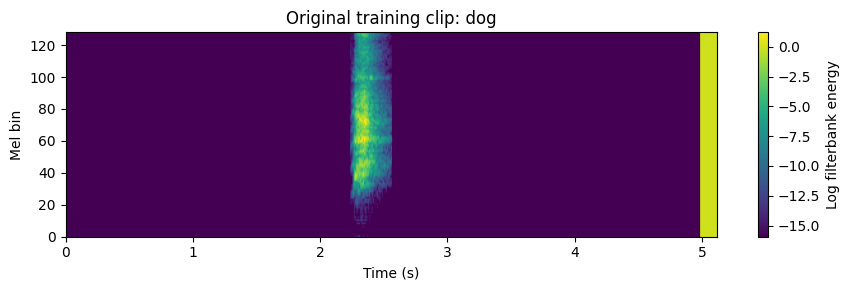

Input shape: (512, 128) | normalisation: -4.2677393 4.5689974


In [19]:
for name in ["config.json", "preprocessor_config.json"]:
    download_file(f"https://huggingface.co/{MODEL_ID}/resolve/{MODEL_REV}/{name}", MODEL_DIR/name)
preprocessor_config = json.loads((MODEL_DIR/"preprocessor_config.json").read_text())
NORM_MEAN = float(preprocessor_config["mean"])
NORM_STD = float(preprocessor_config["std"])
assert NORM_STD > 0

def load_audio(path):
    waveform, sr = sf.read(path, dtype="float32", always_2d=True)
    waveform = waveform.mean(axis=1)
    assert len(waveform) > 0 and np.isfinite(waveform).all()
    x = torch.from_numpy(waveform)
    if sr != SAMPLE_RATE: x = torchaudio.functional.resample(x, sr, SAMPLE_RATE)
    x = x - x.mean()
    return (x.numpy()*WAVEFORM_GAIN).astype(np.float32)

def logmel(waveform, normalise=True):
    x = torch.as_tensor(np.asarray(waveform), dtype=torch.float32).reshape(1,-1)
    x = x - x.mean()
    fb = torchaudio.compliance.kaldi.fbank(x, htk_compat=True, sample_frequency=SAMPLE_RATE,
        use_energy=False, window_type="hanning", num_mel_bins=MEL_BINS,
        dither=0.0, frame_length=25.0, frame_shift=10.0)
    fb = torch.nn.functional.pad(fb, (0,0,0,max(0,FRAMES-fb.shape[0])))[:FRAMES]
    if normalise: fb = (fb - NORM_MEAN)/(2*NORM_STD)
    assert fb.shape == (FRAMES,MEL_BINS) and torch.isfinite(fb).all()
    return fb

# Decode/check EVERY selected clip, not only the example.
for row in tqdm(meta.itertuples(), total=len(meta), desc="Audio checks"):
    audio = load_audio(row.path)
    assert abs(len(audio)/SAMPLE_RATE - 5.0) < 0.02
example = train_meta.iloc[0]
example_audio = load_audio(example.path)
example_spec = logmel(example_audio, normalise=False)
fig, ax = plt.subplots(figsize=(9,3))
im=ax.imshow(example_spec.T, origin="lower", aspect="auto", extent=[0,FRAMES*.01,0,MEL_BINS])
ax.set(xlabel="Time (s)", ylabel="Mel bin", title=f"Original training clip: {example.category}")
fig.colorbar(im, ax=ax, label="Log filterbank energy"); fig.tight_layout()
fig.savefig(RUN_DIR/"step1_spectrogram.png", dpi=150); plt.show()
display(Audio(example_audio, rate=SAMPLE_RATE))
print("Input shape:", tuple(logmel(example_audio).shape), "| normalisation:", NORM_MEAN, NORM_STD)


## Step 2 — Extract and save frozen AST features

The checkpoint was trained on AudioSet, not ESC-50. We load its weights with `safetensors`. We remove the AudioSet classifier and use the mean of the final CLS and distillation-token representations, giving 768 features.

The checkpoint expects 1,024 frames. To support the proposal's 512 frames, we **centre-crop the temporal positional embeddings**, following the original AST implementation. We retain the pretrained patch projection and both special tokens. We do not randomly replace a mismatched positional layer.

The cache records waveform hashes, checkpoint hashes, preprocessing, software versions, and filter settings. Changing those settings creates a new cache key. Cache writes are atomic and can resume after interruption.


In [20]:
weights_path = download_file(
    f"https://huggingface.co/{MODEL_ID}/resolve/{MODEL_REV}/model.safetensors",
    MODEL_DIR/"model.safetensors")
weights_hash = file_sha256(weights_path)
loaded = ASTForAudioClassification.from_pretrained(
    str(MODEL_DIR), use_safetensors=True, local_files_only=True, attn_implementation="sdpa")
ast_model = loaded.audio_spectrogram_transformer
# Explicit, checked adaptation from 12 x 101 patch positions to 12 x 50.
cfg = ast_model.config
assert cfg.hidden_size == 768 and cfg.num_mel_bins == MEL_BINS and cfg.patch_size == 16
old_f = (cfg.num_mel_bins-cfg.patch_size)//cfg.frequency_stride+1
old_t = (cfg.max_length-cfg.patch_size)//cfg.time_stride+1
new_t = (FRAMES-cfg.patch_size)//cfg.time_stride+1
positions = ast_model.embeddings.position_embeddings.detach()
assert positions.shape == (1,old_f*old_t+2,768) and new_t <= old_t
patch_positions = positions[:,2:].reshape(1,old_f,old_t,768)
start = old_t//2-new_t//2
cropped = patch_positions[:,:,start:start+new_t,:].reshape(1,old_f*new_t,768)
ast_model.embeddings.position_embeddings = nn.Parameter(
    torch.cat([positions[:,:2],cropped],dim=1), requires_grad=False)
cfg.max_length = FRAMES
ast_model.requires_grad_(False).eval().to(DEVICE)
del loaded
assert not any(p.requires_grad for p in ast_model.parameters())

preprocessing_signature = dict(sr=SAMPLE_RATE, bins=MEL_BINS, frames=FRAMES,
    frame_ms=25, hop_ms=10, dither=0, window="hanning", demean=True,
    normalization="fixed_AudioSet", mean=NORM_MEAN, std=NORM_STD, waveform_gain=WAVEFORM_GAIN,
    patch_size=16, position_adaptation="centre_crop_time",
    embedding="mean_final_cls_and_distillation")
feature_signature = dict(model_revision=MODEL_REV, weights_sha256=weights_hash,
    dataset_revision=ESC_REV, preprocessing=preprocessing_signature,
    libraries={k:runtime[k] for k in ["torch","torchaudio","transformers","numpy","scipy","soundfile"]},
    pipeline_version=PIPELINE_VERSION)
save_json(RUN_DIR/"feature_provenance.json",feature_signature)

@torch.inference_mode()
def embed_waveform(waveform):
    values=logmel(waveform).unsqueeze(0).to(DEVICE)
    features=ast_model(input_values=values).pooler_output[0].cpu().numpy()
    assert features.shape == (768,) and np.isfinite(features).all()
    return features.astype(np.float32)

start_time=time.perf_counter()
first_feature=embed_waveform(example_audio)
seconds_per_clip=time.perf_counter()-start_time
repeat_feature=embed_waveform(example_audio)
np.testing.assert_allclose(first_feature,repeat_feature,atol=1e-5,rtol=1e-5)
print("Feature shape:", first_feature.shape, "| first inference seconds:", round(seconds_per_clip,2))
print("Rough total extraction minutes for this mode:",
      round(seconds_per_clip*(len(meta)+2*len(train_meta)+2*len(val_meta)+4*len(test_meta))/60,1))
print("Estimate includes all filter views; warm-up and caching change actual runtime.")


Feature shape: (768,) | first inference seconds: 0.28
Rough total extraction minutes for this mode: 32.0
Estimate includes all filter views; warm-up and caching change actual runtime.


In [21]:
# Step 4 defines this function for filtered views. Clean extraction needs no filter bank.
def transform_waveform(waveform, view_id):
    if view_id == "clean": return waveform
    return apply_microphone_filter(waveform, view_id)

def extract_features(frame):
    """Rows require filename, path, audio_sha256, label, view_id, src_file, split."""
    torch.set_num_threads(EXTRACTION_THREADS)
    result=[]; started=time.perf_counter(); computed=0
    for row in tqdm(frame.itertuples(),total=len(frame),desc="AST feature cache"):
        filt = None if row.view_id == "clean" else FILTER_CONFIG[row.view_id]
        key=digest(dict(signature=feature_signature,audio_sha256=row.audio_sha256,
                        view=row.view_id,filter=filt))
        destination=CACHE_DIR/(key+".npy")
        if destination.exists():
            z=np.load(destination,allow_pickle=False)
            assert z.shape==(768,) and np.isfinite(z).all(), f"Invalid cache: {destination}"
        else:
            waveform=transform_waveform(load_audio(row.path),row.view_id)
            z=embed_waveform(waveform);computed+=1
            temporary=destination.with_suffix(".tmp")
            with temporary.open("wb") as f: np.save(f,z,allow_pickle=False)
            temporary.replace(destination)
        result.append(z)
    elapsed=time.perf_counter()-started
    print(f"{len(result)} rows; {computed} newly computed; {elapsed:.1f} seconds.")
    return np.stack(result).astype(np.float32)

clean_rows=meta.assign(view_id="clean")
X_clean=extract_features(clean_rows)
clean_lookup={f:z for f,z in zip(clean_rows.filename,X_clean)}

def clean_matrix(frame): return np.stack([clean_lookup[f] for f in frame.filename])
X_train,X_val,X_test=[clean_matrix(f) for f in [train_meta,val_meta,test_meta]]
y_train,y_val,y_test=[f.label.to_numpy(dtype=np.int64) for f in [train_meta,val_meta,test_meta]]
print("Feature matrices:", X_train.shape,X_val.shape,X_test.shape)


AST feature cache: 100%|██████████| 1991/1991 [06:44<00:00,  4.92it/s]

1991 rows; 1941 newly computed; 404.5 seconds.
Feature matrices: (1196, 768) (397, 768) (398, 768)


## Step 3 — Train a linear classifier using three seeds

We train only a 768-to-class-count linear layer. The objective is mean cross-entropy plus an explicit L2 penalty on the weight matrix. Adam updates the weights. Early stopping and the choice of L2 coefficient use validation macro F1, with validation cross-entropy as a tie-breaker.

Each seed changes classifier initialisation and training order. It does not change the data split. We report sample standard deviation across seeds (`ddof=1`). We centre features using the **original training mean only**; no feature standardisation or post-projection normalisation is added.

The pilot intentionally trains on three folds and retains a separate validation fold. It does not refit on four folds or reproduce the full fine-tuning experiment from the AST paper. A small mel-CNN and complete five-fold CV are later tasks, outside these five steps.


In [22]:
LABELS=np.arange(N_CLASSES)

def metrics(y,p):
    return {"accuracy":float(accuracy_score(y,p)),
            "macro_f1":float(f1_score(y,p,labels=LABELS,average="macro",zero_division=0))}

@torch.inference_mode()
def predict_head(head,X):
    return head(torch.as_tensor(np.asarray(X),dtype=torch.float32)).argmax(1).numpy()

@torch.inference_mode()
def validation_score(head,X,y,groups=None):
    logits=head(torch.as_tensor(np.asarray(X),dtype=torch.float32))
    predictions=logits.argmax(1).numpy()
    if groups is None: groups=np.zeros(len(y),dtype=int)
    score=np.mean([metrics(y[groups==g],predictions[groups==g])["macro_f1"] for g in np.unique(groups)])
    loss=nn.functional.cross_entropy(logits,torch.as_tensor(y,dtype=torch.long)).item()
    return float(score),float(loss)

def train_head(X,y,V,vy,seed,l2,groups=None):
    torch.set_num_threads(1)
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    head=nn.Linear(X.shape[1],N_CLASSES)
    optimizer=torch.optim.Adam(head.parameters(),lr=LR)
    Xt=torch.as_tensor(np.asarray(X),dtype=torch.float32)
    yt=torch.as_tensor(y,dtype=torch.long)
    generator=torch.Generator().manual_seed(seed)
    best_key=(-np.inf,-np.inf);best_state=None;history=[];stale=0
    for epoch in range(1,MAX_EPOCHS+1):
        head.train();total=0.0
        for batch in torch.randperm(len(y),generator=generator).split(HEAD_BATCH):
            optimizer.zero_grad(set_to_none=True)
            logits=head(Xt[batch])
            ce=nn.functional.cross_entropy(logits,yt[batch])
            loss=ce+l2*head.weight.square().sum()
            loss.backward();optimizer.step();total+=float(ce.detach())*len(batch)
        head.eval()
        score,val_ce=validation_score(head,V,vy,groups)
        history.append(dict(epoch=epoch,train_ce=total/len(y),val_ce=val_ce,val_macro_f1=score))
        key=(score,-val_ce)
        if key>best_key:
            best_key=key;best_state=copy.deepcopy(head.state_dict());best_epoch=epoch;stale=0
        else: stale+=1
        if stale>=PATIENCE: break
    head.load_state_dict(best_state);head.eval()
    return dict(head=head,score=best_key[0],val_ce=-best_key[1],epoch=best_epoch,
                l2=float(l2),seed=int(seed),history=pd.DataFrame(history))

# This mean is reused for every matched comparison.
train_mean=X_train.mean(axis=0,dtype=np.float64).astype(np.float32)
baseline_models={};baseline_rows=[]
for seed in SEEDS:
    candidates=[train_head(X_train-train_mean,y_train,X_val-train_mean,y_val,seed,l2) for l2 in L2_GRID]
    best=max(candidates,key=lambda c:(c["score"],-c["val_ce"]))
    baseline_models[seed]=best
    predictions=predict_head(best["head"],X_test-train_mean)
    baseline_rows.append(dict(seed=seed,l2=best["l2"],epoch=best["epoch"],**metrics(y_test,predictions)))
    best["history"].to_csv(RUN_DIR/f"baseline_seed{seed}_history.csv",index=False)
baseline_table=pd.DataFrame(baseline_rows)
display(baseline_table)
display(baseline_table[["accuracy","macro_f1"]].agg(["mean","std"])*100)
print("SMOKE WORKFLOW CHECK ONLY" if MODE=="smoke" else "SINGLE OUTER FOLD PILOT — not five-fold CV")


,seed,l2,epoch,accuracy,macro_f1
0,42,0.0010,36,0.954774,0.954576
1,123,0.0001,17,0.952261,0.952117
2,999,0.0100,26,0.962312,0.962521


,accuracy,macro_f1
mean,95.644891,95.640484
std,0.523032,0.543764


SINGLE OUTER FOLD PILOT — not five-fold CV


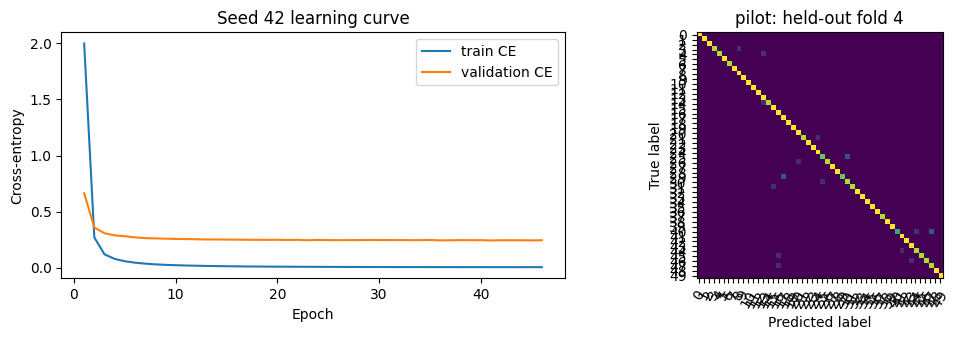

In [23]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
history=baseline_models[SEEDS[0]]["history"]
axes[0].plot(history.epoch,history.train_ce,label="train CE")
axes[0].plot(history.epoch,history.val_ce,label="validation CE")
axes[0].set(xlabel="Epoch",ylabel="Cross-entropy",title=f"Seed {SEEDS[0]} learning curve");axes[0].legend()
cm=confusion_matrix(y_test,predict_head(baseline_models[SEEDS[0]]["head"],X_test-train_mean),labels=LABELS)
# Fifty text labels do not fit; show indexed classes in pilot mode.
ConfusionMatrixDisplay(cm,display_labels=class_names if N_CLASSES<=10 else LABELS).plot(
    ax=axes[1],colorbar=False,xticks_rotation=60,include_values=N_CLASSES<=10)
axes[1].set_title(f"{MODE}: held-out fold {TEST_FOLD}")
fig.tight_layout();fig.savefig(RUN_DIR/"step3_baseline.png",dpi=160);plt.show()


## Step 4 — Simulate microphones and train an augmentation baseline

These are **synthetic frequency-response filters**, not measured microphones. Each FIR filter is symmetric; we compensate its delay, preserve waveform length, and match RMS level. The common 0.1 waveform gain provides headroom without changing the level ratio between paired recordings. If matching would exceed peak 0.999, we reduce the filtered signal and record that level matching was limited. No samples are hard-clipped.

We fix **six training, two validation, and four test filters**. Every training clip gets two training-filter views, selected deterministically from its filename. All augmented methods use exactly the same saved views. Validation-filter and test-filter views never enter classifier training or CPCP fitting. Filter family/parameter choices are fixed before looking at test scores.

This tests unseen responses drawn from a related synthetic family. It does not establish robustness to real unseen devices. Three classifier seeds do not measure uncertainty over a new choice of filters.


In [24]:
FREQUENCIES=[0,80,250,1000,3000,6000,8000]
GAINS_DB=[
 [0,0,0,-1,-3,-6,-8], [-8,-6,-3,0,0,0,0], [-3,-2,0,3,1,-2,-4],
 [2,2,1,0,-1,-2,-3], [-2,-1,0,-3,2,3,1], [0,1,2,0,-2,1,0],
 [-5,-4,-1,2,0,-3,-5], [1,1,-2,0,3,1,-2],
 [0,0,-2,-3,-5,-9,-12], [-12,-8,-4,-1,1,2,2],
 [-4,-2,2,4,-1,-4,-6], [3,2,-3,-2,4,2,-3],
]
FILTER_CONFIG={f"mic_{i:02d}":dict(frequencies=FREQUENCIES,gains_db=gains,taps=129,
    sr=SAMPLE_RATE,rms_match=True,peak_limit=0.999,delay_compensation=True)
    for i,gains in enumerate(GAINS_DB)}
TRAIN_FILTERS=list(FILTER_CONFIG)[:6]
VAL_FILTERS=list(FILTER_CONFIG)[6:8]
TEST_FILTERS=list(FILTER_CONFIG)[8:]
assert not(set(TRAIN_FILTERS)&set(VAL_FILTERS) or set(TRAIN_FILTERS)&set(TEST_FILTERS)
           or set(VAL_FILTERS)&set(TEST_FILTERS))
FILTER_TAPS={name:signal.firwin2(config["taps"],config["frequencies"],
    10**(np.array(config["gains_db"])/20),fs=SAMPLE_RATE) for name,config in FILTER_CONFIG.items()}
filter_audit=[]

def apply_microphone_filter(waveform,view_id,record=False):
    x=np.asarray(waveform,dtype=np.float64);taps=FILTER_TAPS[view_id]
    delay=(len(taps)-1)//2
    filtered=signal.fftconvolve(x,taps,mode="full")[delay:delay+len(x)]
    before=float(np.sqrt(np.mean(x*x)));after=float(np.sqrt(np.mean(filtered*filtered)))
    if after>1e-12: filtered*=before/after
    peak=float(np.max(np.abs(filtered)));limited=peak>0.999
    if limited: filtered*=0.999/peak
    assert len(filtered)==len(x) and np.isfinite(filtered).all()
    assert np.max(np.abs(filtered))<=1.000001
    if record: filter_audit.append(dict(filter=view_id,rms_original=before,
        rms_filtered=float(np.sqrt(np.mean(filtered*filtered))),rms_match_limited=limited))
    return filtered.astype(np.float32)

def two_training_filters(filename):
    local_seed=int(hashlib.sha256(("assignment_v1:"+filename).encode()).hexdigest()[:8],16)
    return np.random.default_rng(local_seed).choice(TRAIN_FILTERS,size=2,replace=False).tolist()

def make_views(frame,kind):
    rows=[]
    for _,row in frame.iterrows():
        views=(["clean"]+two_training_filters(row.filename) if kind=="train" else
               VAL_FILTERS if kind=="val" else TEST_FILTERS)
        for view in views:
            rec=row.to_dict();rec["view_id"]=view;rows.append(rec)
    return pd.DataFrame(rows).reset_index(drop=True)

train_views=make_views(train_meta,"train")
val_views=make_views(val_meta,"val")
test_views=make_views(test_meta,"test")
assert set(train_views.view_id)<=set(TRAIN_FILTERS+["clean"])
assert set(val_views.view_id)==set(VAL_FILTERS) and set(test_views.view_id)==set(TEST_FILTERS)
assert not(set(train_views.src_file)&set(test_views.src_file))
for name,frame in [("train",train_views),("val",val_views),("test",test_views)]:
    frame.to_csv(RUN_DIR/f"{name}_view_manifest.csv",index=False)
save_json(RUN_DIR/"filters.json",dict(definitions=FILTER_CONFIG,train=TRAIN_FILTERS,val=VAL_FILTERS,test=TEST_FILTERS))

# Test delay compensation independently using a centred impulse.
impulse=np.zeros(2001);impulse[1000]=0.1
for name,taps in FILTER_TAPS.items():
    assert np.allclose(taps,taps[::-1])
    out=apply_microphone_filter(impulse,name)
    assert np.allclose(out[936:1065],out[936:1065][::-1],atol=1e-6)
    assert len(out)==len(impulse)
# Audit all selected non-clean views even if their AST feature is already cached.
for frame in [train_views[train_views.view_id.ne("clean")],val_views,test_views]:
    for row in frame.itertuples(): apply_microphone_filter(load_audio(row.path),row.view_id,record=True)
audit=pd.DataFrame(filter_audit);audit.to_csv(RUN_DIR/"filter_level_audit.csv",index=False)
matched=audit[~audit.rms_match_limited & audit.rms_original.gt(1e-10)]
np.testing.assert_allclose(matched.rms_original,matched.rms_filtered,rtol=1e-6,atol=1e-10)
print("RMS-match-limited views:",int(audit.rms_match_limited.sum()),"of",len(audit))
print("Augmented training rows:",len(train_views),"| validation-filter rows:",len(val_views),"| test-filter rows:",len(test_views))


RMS-match-limited views: 0 of 4778
Augmented training rows: 3588 | validation-filter rows: 794 | test-filter rows: 1592


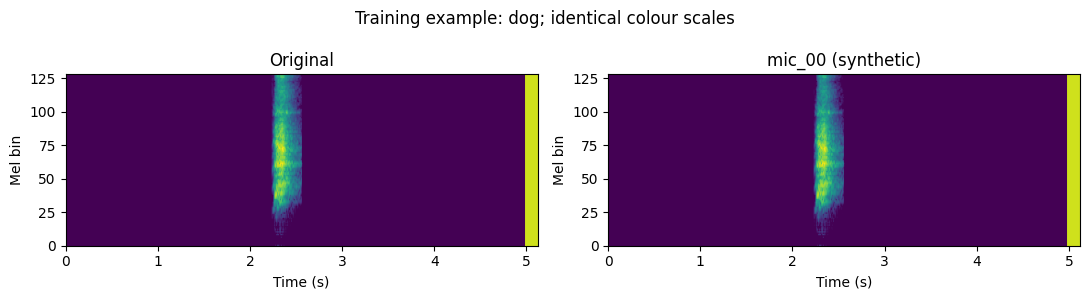

AST feature cache: 100%|██████████| 3588/3588 [07:30<00:00,  7.97it/s]


3588 rows; 2332 newly computed; 450.3 seconds.


AST feature cache: 100%|██████████| 794/794 [02:33<00:00,  5.17it/s]


794 rows; 774 newly computed; 153.5 seconds.


AST feature cache: 100%|██████████| 1592/1592 [05:17<00:00,  5.02it/s]


1592 rows; 1552 newly computed; 317.1 seconds.


,seed,l2,epoch,val_filter_macro_f1,val_clean_accuracy
0,42,0.01,4,0.932904,0.919395
1,123,0.01,3,0.934346,0.929471
2,999,0.01,4,0.933346,0.929471


These are validation scores. They select settings; final test comparisons follow.


In [25]:
# Use a TRAINING filter and clip for a development visualisation.
view=TRAIN_FILTERS[0]
filtered_example=apply_microphone_filter(example_audio,view)
a,b=[logmel(x,normalise=False).numpy().T for x in [example_audio,filtered_example]]
fig,axes=plt.subplots(1,2,figsize=(11,3))
vmin,vmax=min(a.min(),b.min()),max(a.max(),b.max())
for ax,spec,title in zip(axes,[a,b],["Original",view+" (synthetic)"]):
    ax.imshow(spec,origin="lower",aspect="auto",vmin=vmin,vmax=vmax,extent=[0,FRAMES*.01,0,MEL_BINS])
    ax.set(xlabel="Time (s)",ylabel="Mel bin",title=title)
fig.suptitle(f"Training example: {example.category}; identical colour scales")
fig.tight_layout();fig.savefig(RUN_DIR/"step4_original_vs_filtered.png",dpi=160);plt.show()
display(Audio(filtered_example,rate=SAMPLE_RATE))

X_aug=extract_features(train_views);y_aug=train_views.label.to_numpy(dtype=np.int64)
X_vf=extract_features(val_views);y_vf=val_views.label.to_numpy(dtype=np.int64)
X_tf=extract_features(test_views);y_tf=test_views.label.to_numpy(dtype=np.int64)
val_groups=val_views.view_id.to_numpy()
# Exact pairing, rather than subtracting unrelated rows.
paired_mask=train_views.view_id.ne("clean").to_numpy()
X_pairs_original=np.stack([clean_lookup[f] for f in train_views.loc[paired_mask,"filename"]])
paired_differences=X_aug[paired_mask]-X_pairs_original
assert len(paired_differences)==2*len(train_meta)

augmented_models={}
for seed in SEEDS:
    candidates=[train_head(X_aug-train_mean,y_aug,X_vf-train_mean,y_vf,seed,l2,val_groups) for l2 in L2_GRID]
    best=max(candidates,key=lambda c:(c["score"],-c["val_ce"]))
    best["clean_val_accuracy"]=metrics(y_val,predict_head(best["head"],X_val-train_mean))["accuracy"]
    augmented_models[seed]=best
    best["history"].to_csv(RUN_DIR/f"augmentation_seed{seed}_history.csv",index=False)
display(pd.DataFrame([dict(seed=s,l2=b["l2"],epoch=b["epoch"],
    val_filter_macro_f1=b["score"],val_clean_accuracy=b["clean_val_accuracy"])
    for s,b in augmented_models.items()]))
print("These are validation scores. They select settings; final test comparisons follow.")


## Step 5 — Implement CPCP and compare it fairly

Let rows of $X$ contain original training embeddings and let $\mu$ be their mean. Compute centred class means and an orthonormal basis $Q$ for their span. For each training pair, form a difference row $d=z_{\text{filtered}}-z_{\text{original}}$.

Remove protected components from the paired differences:
$$D_\perp=D-(DQ)Q^\top.$$
The top $k$ right singular vectors of $D_\perp$ form columns of $U$. Transform an embedding row by
$$z_{\text{CPCP}}=(z-\mu)-[(z-\mu)U]U^\top.$$

For the **unprotected** baseline, derive $U$ directly from $D$. For **augmentation alone**, use $k=0$. Every augmented method uses the same clips, two filtered training views, optimiser, L2 grid, seeds, and stopping rule. Both projection families get the same rank grid.

CPCP protects class-mean directions, not every useful feature. Therefore, candidate selection also requires clean validation accuracy to remain within 1 percentage point of augmentation alone. This constraint is applied to both projection families. If no positive rank qualifies, rank zero remains available. A rank-zero winner means that this run did not support removing any directions.

We first test the algebra on synthetic arrays, **without treating that check as a sound-classification result**.


In [26]:
def nonzero_basis(rows):
    rows=np.asarray(rows,dtype=np.float64)
    with threadpool_limits(limits=1): _,s,Vt=np.linalg.svd(rows,full_matrices=False)
    tol=max(rows.shape)*np.finfo(np.float64).eps*(s[0] if len(s) else 0)
    return Vt[s>tol].T.copy()

class ChannelProjection:
    def __init__(self,rank=0,protect=True):
        self.requested_rank=int(rank);self.protect=bool(protect)
    def fit(self,original,y,differences):
        original=np.asarray(original,dtype=np.float64)
        self.mean=original.mean(axis=0)
        means=np.stack([original[y==c].mean(axis=0)-self.mean for c in np.unique(y)])
        self.Q=nonzero_basis(means)
        D=np.asarray(differences,dtype=np.float64)
        residual=D-(D@self.Q)@self.Q.T if self.protect else D
        basis=nonzero_basis(residual)
        self.available_rank=basis.shape[1]
        self.effective_rank=min(self.requested_rank,self.available_rank)
        U=basis[:,:self.effective_rank]
        if self.protect and U.shape[1]:
            # Remove numerical drift and restore orthonormal columns.
            U=U-self.Q@(self.Q.T@U)
            U=np.linalg.qr(U,mode="reduced")[0]
        self.U=U
        return self
    def transform(self,X):
        centred=np.asarray(X,dtype=np.float64)-self.mean
        return (centred-(centred@self.U)@self.U.T).astype(np.float32)

rng=np.random.default_rng(7)
synthetic_X=rng.normal(size=(90,24));synthetic_y=np.repeat(np.arange(3),30)
synthetic_D=rng.normal(size=(180,24))
check=ChannelProjection(4,True).fit(synthetic_X,synthetic_y,synthetic_D)
np.testing.assert_allclose(check.Q.T@check.U,0,atol=1e-10)
np.testing.assert_allclose(check.U.T@check.U,np.eye(4),atol=1e-10)
P=np.eye(24)-check.U@check.U.T
np.testing.assert_allclose(P@P,P,atol=1e-10)
transformed=check.transform(synthetic_X)
for cls in np.unique(synthetic_y):
    np.testing.assert_allclose(transformed[synthetic_y==cls].mean(0),
        synthetic_X[synthetic_y==cls].mean(0)-check.mean,atol=1e-6)
identity=ChannelProjection(0,True).fit(synthetic_X,synthetic_y,synthetic_D)
np.testing.assert_allclose(identity.transform(synthetic_X),synthetic_X-identity.mean,atol=1e-6)
print("Passed: orthogonality, orthonormality, idempotence, class-mean preservation, rank-zero identity.")


Passed: orthogonality, orthonormality, idempotence, class-mean preservation, rank-zero identity.


### Fit and select projection models
This cell may take several minutes in pilot mode. It never uses test labels or test-filter scores. All selected settings and all validation candidates are saved. Projection fitting uses original training class means and paired training differences only.


In [28]:
# Fit the deterministic bases once; classifier seeds do not change these fixed training pairs.
projections={}
for family,protected in [("unprotected",False),("cpcp",True)]:
    for k in RANK_GRID:
        projections[(family,k)]=ChannelProjection(k,protected).fit(X_train,y_train,paired_differences)
# Real-data algebra check before any classifier comparison.
for (family,k),proj in projections.items():
    if family=="cpcp" and proj.effective_rank:
        np.testing.assert_allclose(proj.Q.T@proj.U,0,atol=1e-8)
        for cls in LABELS:
            np.testing.assert_allclose(proj.transform(X_train[y_train==cls]).mean(0),
                X_train[y_train==cls].mean(axis=0,dtype=np.float64)-proj.mean,atol=2e-5)

selected={};search_rows=[]
for seed in SEEDS:
    for family in ["unprotected","cpcp"]:
        aug=augmented_models[seed]
        # Reuse the exact augmentation-only classifier for rank zero.
        best=dict(aug,projection=projections[(family,0)],requested_rank=0)
        best_key=(best["score"],-best["val_ce"],0)
        search_rows.append(dict(seed=seed,family=family,requested_rank=0,effective_rank=0,
            l2=best["l2"],epoch=best["epoch"],val_macro_f1=best["score"],
            clean_val_accuracy=aug["clean_val_accuracy"],eligible=True))
        seen_ranks={0}
        for k in RANK_GRID:
            proj=projections[(family,k)]
            if proj.effective_rank in seen_ranks: continue
            seen_ranks.add(proj.effective_rank)
            A,V,C=[proj.transform(x) for x in [X_aug,X_vf,X_val]]
            for l2 in L2_GRID:
                cand=train_head(A,y_aug,V,y_vf,seed,l2,val_groups)
                clean_acc=metrics(y_val,predict_head(cand["head"],C))["accuracy"]
                eligible=clean_acc>=aug["clean_val_accuracy"]-CLEAN_TOLERANCE-1e-12
                search_rows.append(dict(seed=seed,family=family,requested_rank=k,
                    effective_rank=proj.effective_rank,l2=l2,epoch=cand["epoch"],
                    val_macro_f1=cand["score"],clean_val_accuracy=clean_acc,eligible=eligible))
                key=(cand["score"],-cand["val_ce"],-proj.effective_rank)
                if eligible and key>best_key:
                    best=dict(cand,projection=proj,requested_rank=k,clean_val_accuracy=clean_acc)
                    best_key=key
        selected[(family,seed)]=best
        print(f"{family}, seed {seed}: rank {best['projection'].effective_rank}, L2 {best['l2']}, epoch {best['epoch']}")
search_table=pd.DataFrame(search_rows)
search_table.to_csv(RUN_DIR/"projection_validation_search.csv",index=False)
display(search_table.groupby(["family","requested_rank"]).agg(
    mean_val_f1=("val_macro_f1","mean"),eligible_candidates=("eligible","sum")))
print("Rank zero is allowed. It is not evidence of a CPCP improvement.")


unprotected, seed 42: rank 0, L2 0.01, epoch 4
cpcp, seed 42: rank 0, L2 0.01, epoch 4
unprotected, seed 123: rank 16, L2 0.01, epoch 13
cpcp, seed 123: rank 16, L2 0.01, epoch 12
unprotected, seed 999: rank 16, L2 0.01, epoch 17
cpcp, seed 999: rank 8, L2 0.01, epoch 17


mean_val_f1  eligible_candidates
family      requested_rank                                  
cpcp        0                  0.933532                    3
            8                  0.931772                    8
            16                 0.929924                    9
            32                 0.928714                    9
            64                 0.929087                    9
            128                0.928096                    9
unprotected 0                  0.933532                    3
            8                  0.929877                    9
            16                 0.931629                    9
            32                 0.929124                    9
            64                 0.921223                    3
            128                0.919609                    3

Rank zero is allowed. It is not evidence of a CPCP improvement.


### Final held-out evaluation and saved evidence

For each method and seed we compute clean accuracy and macro F1, macro F1 for each of the four unseen filters, their average, and the worst filter. The final table shows means and sample standard deviations across the three seeds. These are **not confidence intervals**.

The clean-accuracy constraint above applies on validation data only; we still report the actual test change, even if it violates that target. With five classes and ten test clips in smoke mode, scores are very unstable. Do not copy smoke scores into the midterm as ESC-50 performance.


In [29]:
def pack_head(head):
    return {"weight":head.weight.detach().numpy(),"bias":head.bias.detach().numpy()}

results=[];prediction_records=[];chosen_records=[]
for seed in SEEDS:
    models={
      "original_only":dict(baseline_models[seed],projection=None),
      "augmentation_only":dict(augmented_models[seed],projection=None),
      "unprotected":selected[("unprotected",seed)],
      "cpcp":selected[("cpcp",seed)],
    }
    for name,entry in models.items():
        proj=entry["projection"]
        transform=(lambda X: X-train_mean) if proj is None else proj.transform
        clean_pred=predict_head(entry["head"],transform(X_test))
        filter_pred=predict_head(entry["head"],transform(X_tf))
        clean_scores=metrics(y_test,clean_pred)
        per_filter={v:metrics(y_tf[test_views.view_id.to_numpy()==v],
                              filter_pred[test_views.view_id.to_numpy()==v])["macro_f1"] for v in TEST_FILTERS}
        result=dict(method=name,seed=seed,clean_accuracy=clean_scores["accuracy"],
            clean_macro_f1=clean_scores["macro_f1"],filter_macro_f1=float(np.mean(list(per_filter.values()))),
            worst_filter_macro_f1=float(min(per_filter.values())),**{v+"_f1":x for v,x in per_filter.items()})
        results.append(result)
        chosen_records.append(dict(method=name,seed=seed,l2=entry["l2"],epoch=entry["epoch"],
            effective_rank=0 if proj is None else proj.effective_rank))
        for frame,pred in [(test_meta.assign(view_id="clean"),clean_pred),(test_views,filter_pred)]:
            for row,prediction in zip(frame.itertuples(),pred):
                prediction_records.append(dict(method=name,seed=seed,filename=row.filename,
                    src_file=row.src_file,fold=row.fold,view_id=row.view_id,
                    true_label=int(row.label),predicted_label=int(prediction)))
        U=np.zeros((768,0)) if proj is None else proj.U
        mu=train_mean if proj is None else proj.mean
        np.savez_compressed(RUN_DIR/f"{name}_seed{seed}.npz",**pack_head(entry["head"]),mean=mu,U=U,
                            class_names=np.asarray(class_names))
        entry["history"].to_csv(RUN_DIR/f"{name}_seed{seed}_history.csv",index=False)

results=pd.DataFrame(results);predictions=pd.DataFrame(prediction_records)
chosen=pd.DataFrame(chosen_records)
results.to_csv(RUN_DIR/"results_by_seed.csv",index=False)
predictions.to_csv(RUN_DIR/"test_predictions.csv",index=False)
chosen.to_csv(RUN_DIR/"selected_settings.csv",index=False)
metric_columns=["clean_accuracy","clean_macro_f1","filter_macro_f1","worst_filter_macro_f1"]
summary=results.groupby("method")[metric_columns].agg(["mean","std"])*100
summary.to_csv(RUN_DIR/"results_mean_std_percent.csv")
formatted=pd.DataFrame({m:summary[m].apply(lambda row:f"{row['mean']:.2f} ± {row['std']:.2f}",axis=1)
                        for m in metric_columns})
display(formatted)
display(chosen)
# Paired differences retain seed correspondence.
pivot=results.pivot(index="seed",columns="method",values="filter_macro_f1")
delta=(pivot.cpcp-pivot.augmentation_only)*100
print("CPCP minus augmentation, test-filter macro F1 percentage points:",delta.round(3).tolist())
print(f"Mean difference: {delta.mean():.3f} pp; sample SD: {delta.std(ddof=1):.3f} pp.")
status="SMOKE ONLY: 5 classes, subset, one outer test fold; not a benchmark." if MODE=="smoke" else (
    "ESC-50 pilot: 50 classes, one outer test fold, three seeds; no four-fold refit or five-fold CV.")
save_json(RUN_DIR/"run_status.json",dict(status="completed",scope=status,rows=len(meta),
    train_clips=len(train_meta),val_clips=len(val_meta),test_clips=len(test_meta),
    completed_steps=[1,2,3,4,5],synthetic_filters=True,backbone_frozen=True))
print(status)
print("Saved evidence:",RUN_DIR)


,clean_accuracy,clean_macro_f1,filter_macro_f1,worst_filter_macro_f1
method,,,,
augmentation_only,95.48 ± 0.50,95.46 ± 0.53,95.17 ± 0.45,94.45 ± 0.55
cpcp,95.31 ± 0.15,95.31 ± 0.14,95.34 ± 0.39,94.69 ± 0.69
original_only,95.64 ± 0.52,95.64 ± 0.54,95.44 ± 0.42,94.93 ± 0.69
unprotected,95.31 ± 0.15,95.29 ± 0.16,95.04 ± 0.48,94.40 ± 0.71


,method,seed,l2,epoch,effective_rank
0,original_only,42,0.0010,36,0
1,augmentation_only,42,0.0100,4,0
2,unprotected,42,0.0100,4,0
3,cpcp,42,0.0100,4,0
4,original_only,123,0.0001,17,0
5,augmentation_only,123,0.0100,3,0
6,unprotected,123,0.0100,13,16
7,cpcp,123,0.0100,12,16
8,original_only,999,0.0100,26,0
9,augmentation_only,999,0.0100,4,0


CPCP minus augmentation, test-filter macro F1 percentage points: [0.0, 0.588, -0.077]
Mean difference: 0.170 pp; sample SD: 0.364 pp.
ESC-50 pilot: 50 classes, one outer test fold, three seeds; no four-fold refit or five-fold CV.
Saved evidence: /Users/masih/Desktop/cisc473_audio/runs/pilot_6ebc9d4851


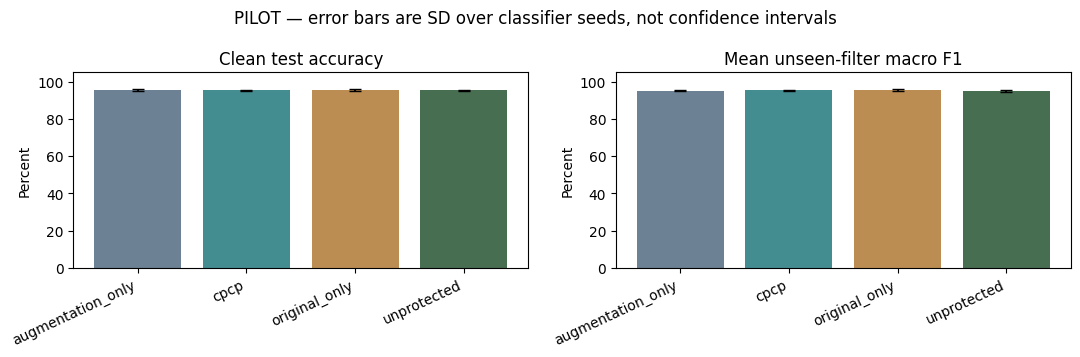

Saved classifier reload check passed.


In [30]:
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
for ax,metric,title in zip(axes,["clean_accuracy","filter_macro_f1"],
                           ["Clean test accuracy","Mean unseen-filter macro F1"]):
    means=summary[metric]["mean"];errors=summary[metric]["std"]
    ax.bar(range(len(means)),means,yerr=errors,capsize=4,color=["#6c8193","#438d91","#bb8d53","#486e52"])
    ax.set_xticks(range(len(means)),means.index,rotation=25,ha="right")
    ax.set(ylabel="Percent",ylim=(0,105),title=title)
fig.suptitle(f"{MODE.upper()} — error bars are SD over classifier seeds, not confidence intervals")
fig.tight_layout();fig.savefig(RUN_DIR/"step5_comparison.png",dpi=170);plt.show()
# Verify a saved classifier reproduces the in-memory original-only predictions.
with np.load(RUN_DIR/f"original_only_seed{SEEDS[0]}.npz",allow_pickle=False) as saved:
    z=X_test-saved["mean"];z=z-(z@saved["U"])@saved["U"].T
    recovered=(z@saved["weight"].T+saved["bias"]).argmax(1)
np.testing.assert_array_equal(recovered,predict_head(baseline_models[SEEDS[0]]["head"],X_test-train_mean))
print("Saved classifier reload check passed.")
